# Concentración de distancias y su efecto en k-NN

Los algoritmos basados en distancias utilizan la proximidad entre observaciones para determinar similitudes. Por ejemplo, k-NN clasifica una observación considerando las clases de sus vecinos más cercanos.

Sin embargo, cuando aumenta el número de dimensiones, las distancias entre observaciones pueden volverse cada vez más similares. Este fenómeno se conoce como concentración de distancias y constituye uno de los problemas asociados a la alta dimensionalidad.

En este experimento estudiaremos cómo cambia la distribución de las distancias al aumentar el número de dimensiones y qué consecuencias tiene para un clasificador k-NN.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import pdist

### ¿Qué ocurre con las distancias cuando aumenta la dimensionalidad?

En un conjunto de datos, cada observación puede describirse mediante un conjunto de características o variables.

Por ejemplo, una observación con dos características puede representarse mediante un punto en un plano. Si añadimos más características, necesitaremos más dimensiones para representar las observaciones.

Cuando trabajamos con dos dimensiones, podemos visualizar fácilmente las distancias entre los puntos. Sin embargo, a medida que aumenta el número de dimensiones, esta representación deja de ser intuitiva.

Uno de los fenómenos que aparece en estos escenarios es la **concentración de distancias**.

In [3]:
np.random.seed(42)

n_observaciones = 500

dimensiones = [2, 5, 10, 20, 50, 100, 200, 500]

resultados = []

for d in dimensiones:

    X = np.random.normal(
        loc=0,
        scale=1,
        size=(n_observaciones, d)
    )

    distancias = pdist(X, metric='euclidean')

    resultados.append({
        'Dimensiones': d,
        'Distancia media': np.mean(distancias),
        'Desviación estándar': np.std(distancias),
        'Distancia mínima': np.min(distancias),
        'Distancia máxima': np.max(distancias),
        'Coeficiente de variación': (
            np.std(distancias) / np.mean(distancias)
        )
    })

df_distancias = pd.DataFrame(resultados)

df_distancias

,Dimensiones,Distancia media,Desviación estándar,Distancia mínima,Distancia máxima,Coeficiente de variación
0,2,1.737019,0.906129,0.003526,6.673893,0.521658
1,5,3.011420,0.970591,0.156274,8.515473,0.322303
2,10,4.453366,1.011526,0.992604,9.197562,0.227137
3,20,6.223790,0.972814,2.078328,11.119022,0.156306
4,50,9.948003,0.978242,6.024545,14.403310,0.098336
5,100,14.120728,0.992179,10.013036,18.898803,0.070264
6,200,19.942008,1.003614,15.935512,25.958264,0.050327
7,500,31.646149,0.992146,27.095426,35.730325,0.031351


### ¿Qué medidas utilizamos?

Para analizar el comportamiento de las distancias calculamos diferentes medidas estadísticas:

- **Distancia media:** representa el valor promedio de las distancias entre los pares de observaciones.
- **Desviación estándar:** mide cuánto se dispersan las distancias respecto a su media.
- **Distancia mínima:** representa la menor distancia encontrada entre dos observaciones.
- **Distancia máxima:** representa la mayor distancia encontrada entre dos observaciones.
- **Coeficiente de variación:** mide la dispersión relativa de las distancias respecto a su media.

El coeficiente de variación permite comparar la dispersión relativa de las distancias entre conjuntos de datos con diferentes dimensionalidades.

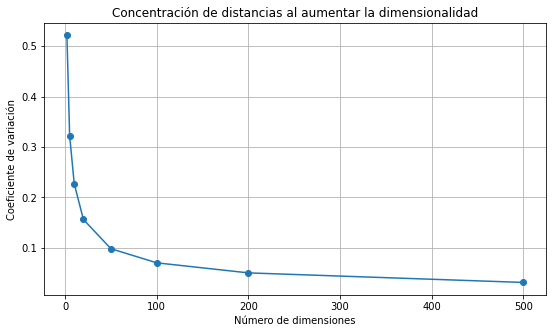

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    df_distancias['Dimensiones'],
    df_distancias['Coeficiente de variación'],
    marker='o'
)

plt.xlabel('Número de dimensiones')
plt.ylabel('Coeficiente de variación')
plt.title('Concentración de distancias al aumentar la dimensionalidad')

plt.grid(True)
plt.show()

Una disminución del coeficiente de variación indica que las distancias se vuelven relativamente más homogéneas.

Este resultado permite comprender por qué, en espacios de alta dimensionalidad, puede resultar más difícil distinguir entre observaciones cercanas y lejanas utilizando únicamente la distancia euclídea.

No obstante, debemos recordar que el comportamiento observado depende de las características del conjunto de datos y de la distribución utilizada para generarlo.

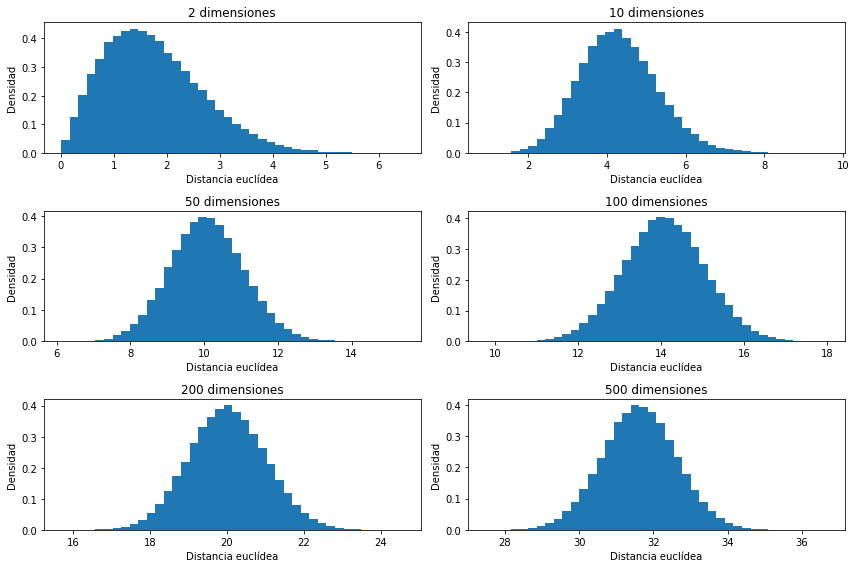

In [ ]:
dimensiones_elegidas = [2, 10, 50,100, 200,500]

fig, axes = plt.subplots(3, 2, figsize=(12, 8))

for ax, d in zip(axes.flatten(), dimensiones_elegidas):

    X = np.random.normal(
        size=(n_observaciones, d)
    )

    distancias = pdist(X, metric='euclidean')

    ax.hist(
        distancias,
        bins=40,
        density=True
    )

    ax.set_title(f'{d} dimensiones')
    ax.set_xlabel('Distancia euclídea')
    ax.set_ylabel('Densidad')

plt.tight_layout()
plt.show()

##  ¿Cómo afecta la dimensionalidad al algoritmo k-NN?

El algoritmo **k-Nearest Neighbors (k-NN)** es un método de aprendizaje supervisado que permite realizar tareas de clasificación y regresión.

En clasificación, el algoritmo identifica las \(k\) observaciones más cercanas a una nueva observación y asigna la clase más frecuente entre sus vecinos.

Por ejemplo, si utilizamos \(k=5\), el algoritmo identifica los cinco vecinos más próximos y determina la clase de la nueva observación mediante votación.


In [8]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [9]:
dimensiones = [2, 5, 10, 20, 50, 100]

resultados_knn = []

for d in dimensiones:

    X, y = make_classification(
        n_samples=1500,
        n_features=d,
        n_informative=2,
        n_redundant=0,
        n_repeated=0,
        n_classes=2,
        class_sep=1.0,
        random_state=42
    )

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.30,
        random_state=42,
        stratify=y
    )

    modelo = Pipeline([
        ('escalado', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ])

    modelo.fit(X_train, y_train)

    predicciones = modelo.predict(X_test)

    accuracy = accuracy_score(y_test, predicciones)

    resultados_knn.append({
        'Dimensiones': d,
        'Accuracy': accuracy
    })

df_knn = pd.DataFrame(resultados_knn)

df_knn

,Dimensiones,Accuracy
0,2,0.964444
1,5,0.920000
2,10,0.833333
3,20,0.782222
4,50,0.693333
5,100,0.600000


In [10]:
frecuencia = pd.Series(y_train).value_counts().sort_index()

porcentaje = (
    pd.Series(y_train)
    .value_counts(normalize=True)
    .sort_index() * 100
)

resumen_clases = pd.DataFrame({
    'Cantidad': frecuencia,
    'Porcentaje': porcentaje
})

display(resumen_clases)

,Cantidad,Porcentaje
0,527,50.190476
1,523,49.809524


#### Métrica de evaluación: Accuracy

Para evaluar el rendimiento del clasificador utilizaremos la exactitud o *accuracy*.

Esta métrica representa la proporción de predicciones correctas respecto al total de predicciones realizadas.

Un valor elevado indica que el clasificador ha realizado correctamente una mayor proporción de predicciones.

En este experimento utilizaremos el mismo tamaño de conjunto de entrenamiento y prueba para todas las dimensionalidades, manteniendo además la misma configuración del algoritmo.

Así podremos comparar el rendimiento de k-NN en los diferentes escenarios.

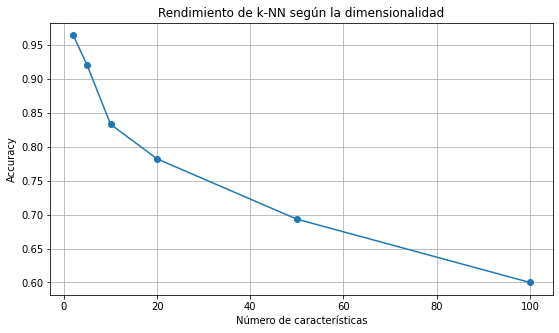

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    df_knn['Dimensiones'],
    df_knn['Accuracy'],
    marker='o'
)

plt.xlabel('Número de características')
plt.ylabel('Accuracy')
plt.title('Rendimiento de k-NN según la dimensionalidad')

plt.grid(True)
plt.show()

La representación permite observar la evolución del rendimiento del clasificador k-NN a medida que aumenta la dimensionalidad.

Si el accuracy disminuye al incorporar características irrelevantes, esto indica que añadir variables que no aportan información útil puede dificultar la clasificación.

Este comportamiento está relacionado con la dependencia de k-NN respecto a las distancias entre observaciones.


### Actividad final
- ¿Qué sucede con las distancias cuando aumenta la dimensionalidad?

- ¿Cómo afecta esto al rendimiento de k-NN?

- ¿Por qué la concentración de distancias puede afectar a los algoritmos basados en proximidad?

- ¿Por qué añadir más características no necesariamente mejora un modelo?

- ¿Qué estrategias podrían utilizarse para reducir los problemas asociados a la alta dimensionalidad?